# Empirical Bayes uncertainty estimation for (U–Th)/He data

This Jupyter notebook demonstrates the use of a form of empirical Bayes resampling (also known as hierarchical Bayes) for more robust (U-Th)/He data uncertainty estimation for use in thermal-history inversions. See [Malinverno and Briggs (2004)](https://doi.org/10.1190/1.1778243) for description of the hierarchical Bayesian method. As described and implemented here, it is particularly suited for zircon datasets (high n) that span a broad range of effective uranium (eU). The aim is to expand uncertainty accounting where the hyperparameters (i.e., observed He dates) will have a prior distribution that expresses their initial uncertainty and a posterior distribution that is determined by the data directly. The individual date errors are treated as hyperparameters drawn from a probability distribution and the variance is used to infer the 'empirical' date uncertainty. This weighted 1σ uncertainty is inferred from the scatter of the data as determined by the standard deviation of the data weighted by a Gaussian kernel in eU space (σeU = 100 ppm). The 100 ppm eU kernel is taken to represent the range over which zircon grains with similar eU should have similar ages. This value was chosen as a good balance because smaller values tend to converge on the internal uncertainty and larger values begin to reduce the influence of individual dates during thermal modelling. The empirical uncertainty is estimated by summing the internal and external uncertainties in quadrature.

Helium data are typically overdispersed with respect to analytical uncertainties (approx. 2-5% for apatite and zircon). The age reproducibility of helium age standards such as the Durango (DUR) apatite and Fish Canyon Tuff (FCT) zircon suggest uncertainties are greater, on the order of 6-7% for apatite and 8-10% for zircon. For more information regarding date reproducibility and ICPMS measurements, see Reiners and Nicolescu (2006) (https://www.geo.arizona.edu/~reiners/arhdl/arhdlrep1.pdf), [Guenthner et al. (2016)](https://doi.org/10.1002/2016GC006311) for U–Th/He, and [Gleadow et al. (2015)](https://doi.org/10.1016/j.epsl.2015.05.003) for FCT specifically. 

These are still likely minimum estimates, since those grains are laboratory standards with well-behaved diffusion behavior demonstrated experimentally. Natural, 'wild' samples typically have total uncertainties that exceed 10% due various reasons such as (unaccounted for) isotopic zoning, imperfect grain measurement/grain morphology characterization for alpha-loss correction, or unidentified mineral or fluid inclusions (to name a few). There is also the possibility for trapping of pre- and post-'closure' 4He in various grain sinks and imperfections that further complicate the age reproducibility of slowly cooled apatite; see [Zeitler et al. (2017)](https://doi.org/10.1016/j.gca.2017.03.041), [McDannell et al. (2018)](https://doi.org/10.1016/j.gca.2017.11.031), and [Guo et al. (2021)](https://doi.org/10.1016/j.gca.2021.07.015) for recent experiments and discussion of He age dispersion and diffusion systematics in apatite.

Note: some publications bin single-grain dates by eU and then average the dates in each bin to create 'synthetic' He dates, but this approach lacks rigor and quickly becomes an arbitrary exercise depending on data quality and quantity. This is even more problematic for apatite dates that normally span a narrow eU range. This is usually carried out for time-temperature (t-T) modelling, however, it removes temporal information and artificially increases date errors, and as a result, makes it easier to meet p-value statistical thresholds of acceptance for pure Monte Carlo modelling. Thus its only purpose is to 'hack' the t-T search and allow more paths to be found more easily. Do not do this. Since most age dispersion is explainable to first-order by the effects of radiation damage on diffusivity, each grain is a separate thermochronometer (that is the advantage of using radiation-damage models in the first place!). Averaging dates results in a loss of valuable t-T information and decreased t-T resolution. Importantly, the empirical Bayes approach retains the observed date calculated from the measured isotopic data but the uncertainties are estimated from the data directly. Error resampling is helpful during t-T modelling when errors are underestimated and prevents the t–T search algorithm from becoming trapped in local minima by reducing overprecision (in the case of learning algorithms such as Markov chain Monte Carlo). A notable point is that the empirical uncertainties only act to assist in improving the search, as the observed age is still the target datum, therefore, it is different from a simple Monte Carlo approach where increasing the uncertainties (or reducing the number of precise data by averaging) actually results in more paths being found and accepted during the random sifting of t-T space.

## Load required Julia packages

In [8]:
## --- Load (and install if neccesary) the StatGeochem package

using Plots, Statistics, StatGeochem

## Enter sample information

First we read in our sample information for completeness and record-keeping purposes for output. This is of course optional, and we could instead just read in ages, actinide concentrations, and uncertainties for simplicity.

sample name; equivalent spherical radius (ESR) or grain halfwidth; U-Th-(Sm) are used for calculating eU;
and the observed uncorrected He age and its corresponding 1σ uncertainty. A row can be added for Sm if required and the eU equation will have to be updated accordingly. See [Cooperdock et al. (2019)](https://gchron.copernicus.org/articles/1/17/2019/), for the most recent and complete eU equation(s) and derivation: eU = U + 0.238 x Th + 0.0012 x Sm

<!-- TAI_MRM20_z4	50.214676	193.694618	111.354468	817.638938	10.911924
TAI_MRM4_z5	43.415044	625.499321	408.494290	1288.377901	18.007095
Unnamed: 0	radius	U_ppm	Th_ppm	uncorrected_date	uncorrected_1s -->

In [18]:
ds = Dict{String, Union{Vector{Float64}, Vector{String}}}()

ds["Unnamed: 0"] = Name=[
    "TAI_MRM1_z1", "TAI_MRM1_z2", "TAI_MRM1_z3", "TAI_MRM2_z1", "TAI_MRM2_z2", "TAI_MRM4_z1", "TAI_MRM4_z2", "TAI_MRM4_z4", "TAI_MRM5_z1", "TAI_MRM5_z2", "TAI_MRM5_z3", 
    "TAI_MRM6_z1", "TAI_MRM6_z2", "TAI_MRM35_z1", "TAI_MRM35_z3", "TAI_MRM35_z4", "TAI_MRM20_z1", "TAI_MRM20_z2", "TAI_MRM8_z1", "TAI_MRM8_z2", "TAI_MRM8_z3", "TAI_MRM8_z4", 
    "TAI_MRM8_z5", "TAI_MRM8_z6", "TAI_MRM17_z1", "TAI_MRM17_z2", "TAI_MRM16_z1", "TAI_MRM16_z2", "TAI_MRM4_z5", "TA_MRM7_z4", "TA_MRM7_z5", "TAI_MRM20_z1", "TAI_MRM20_z2", 
    "TAI_MRM20_z4", "TAI_MRM21_z2", "TA_MRM35_z4", "TA_MRM35_z5", "TAI_MRM1_z4", "TAI_MRM1_z5", "TAI_MRM2_z3", "TAI_MRM2_z4", "TAI_MRM6_z3", "TAI_MRM6_z4", "TAI_MRM7_z1", 
    "TAI_MRM7_z2", "TAI_MRM7_z3", "TAI_MRM21_z1", "TAI_MRM21_z3", "TAI_MRM35_z5", "TAI_MRM35_z6", "TAI_MRM35_z7", "TAI_MRM17_z3", "TAI_MRM16_z3"
]

ds["radius"] = ESR = [
    36.350348, 35.669719, 46.053177, 47.530903, 30.089365, 50.774505, 33.320044, 31.684715, 37.559541, 41.253983, 57.094332, 61.165746, 60.495940, 42.697182, 45.922551, 
    43.203846, 48.911997, 34.905185, 42.336105, 40.152933, 39.605626, 48.303716, 46.800715, 42.990576, 39.071283, 31.497971, 62.143029, 57.299318, 50.214676, 64.228391, 
    76.969028, 48.911997, 34.905185, 50.214676, 46.407495, 79.394246, 73.000588, 35.129671, 72.166558, 34.343442, 28.729569, 70.360033, 32.223505, 31.641169, 32.140873, 
    29.640495, 45.878913, 44.353233, 158.438580, 52.086983, 58.909666, 38.355545, 42.489802
]

ds["U_ppm"] = U = [
    227.768724, 279.730221, 174.803634, 556.570665, 296.246733, 601.498635, 1490.153803, 1445.960050, 1102.917529, 573.594680, 455.485630, 256.034014, 362.920170, 
    98.418198, 94.067034, 404.534679, 195.504453, 378.801086, 279.740998, 429.923443, 1365.495391, 695.908140, 341.580339, 397.129218, 4415.920593, 2798.007628, 723.777407, 
    1699.637494, 193.694618, 721.885851, 654.455487, 574.209527, 969.591488, 193.694618, 231.254813, 103.953980, 85.071847, 318.890236, 262.024719, 868.862161, 308.334408, 
    415.936668, 435.135447, 808.421281, 1150.495298, 1258.706157, 336.472970, 259.003323, 155.602355, 103.387744, 370.245939, 1504.824909, 858.677698
]

ds["Th_ppm"] = Th = [
    127.097946, 100.422081, 107.683401, 140.559155, 61.004882, 87.245551, 308.033809, 411.064400, 590.111953, 428.676950, 463.358875, 176.324114, 205.569191, 
    31.167900, 37.319793, 76.196841, 81.291058, 119.490228, 123.030115, 230.735020, 705.183618, 345.533791, 250.099219, 156.981847, 373.574604, 367.134223, 219.245727, 
    943.286022, 111.354468, 310.217869, 1107.094242, 141.231269, 472.189145, 111.354468, 131.783240, 35.280772, 24.012744, 115.647298, 163.292784, 319.927327, 76.554461, 
    301.848195, 300.771423, 1734.537737, 319.316056, 57.095538, 223.340093, 128.009119, 35.713491, 30.559556, 64.957950, 407.615472, 264.215583
]

ds["uncorrected_date"] = Age = [
    601.079624, 490.431492, 621.976075, 525.437954, 654.262651, 519.737959, 96.541949, 156.279406, 206.835774, 313.105551, 510.694729, 778.158881, 597.433490, 
    709.262653, 737.061885, 680.318383, 606.885718, 450.782602, 748.964259, 482.387669, 440.290567, 236.273694, 521.718277, 374.297151, 5.296212, 248.306297, 263.384342, 
    77.812576, 817.638938, 88.546118, 165.027266, 222.170519, 174.160164, 817.638938, 702.270880, 771.477717, 697.418114, 421.181874, 568.305729, 279.696384, 559.244283, 
    552.797960, 460.292833, 348.850341, 118.166408, 114.789635, 601.325281, 640.117952, 731.058641, 665.902550, 578.502779, 133.269400, 210.993590
]

ds["uncorrected_1s"] = Age_sigma = [
    9.314291, 10.755377, 9.579657, 7.574441, 11.868029, 9.996310, 1.639312, 3.515129, 3.482635, 5.221890, 6.209667, 10.612406, 10.997252, 14.270506, 13.982308, 
    11.304829, 10.797044, 8.695132, 12.480088, 8.091800, 6.444756, 3.721832, 8.400055, 4.695762, 0.064339, 3.354211, 3.230698, 1.287363, 10.911924, 1.524385, 2.224726, 
    3.800957, 2.282895, 10.911924, 12.041214, 13.704211, 12.654006, 7.900796, 9.379785, 5.245037, 10.761694, 8.957873, 8.676166, 5.192325, 1.785205, 1.669708, 8.692545, 
    10.803029, 10.635528, 11.724431, 11.156879, 1.900601, 3.943335
]
ds["eU [ppm]"] = eU = U+.238*Th

53-element Vector{Float64}:
  258.01803514799997
  303.63067627799995
  200.43228343799998
  590.02374389
  310.765894916
  622.2630761380001
 1563.465849542
 1543.7933772
 1243.364173814
  675.6197941
    ⋮
 1226.492519328
 1272.294895044
  389.627912134
  289.469493322
  164.10216585799998
  110.660918328
  385.70593110000004
 1601.8373913359999
  921.561006754

#### optional: set minimum 1σ error to 5% for zircon date, if not already so

In [33]:
# t = Age_sigma .< (0.05.*Age)
# Age_sigma[t] = (0.05.*Age)[t]

## Calculate the empirical standard deviation on the single-grain dates and plot the results

Standard deviation of the Gaussian kernel in eU space representing the range over which grains with similar eU should have similar ages. Plotting x,y with both internal and empirical date uncertainties. We then export the results and our sample information to a .csv file.

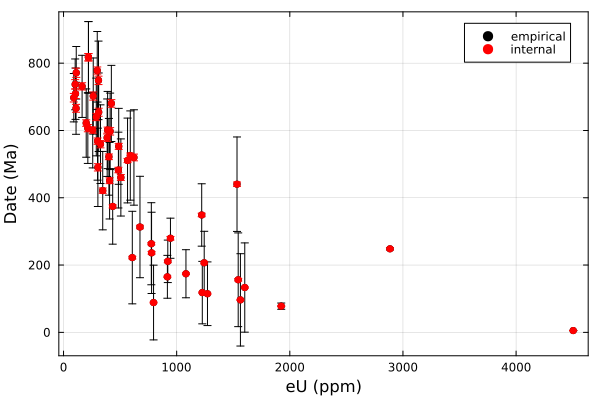

MRM_Age_sigma_empirical:
[112.3, 116.4, 101.6, 132.6, 116.7, 141.7, 137.3, 139.3, 93.52, 150.8, 126.0, 116.1, 113.7, 76.3, 75.45, 113.1, 105.0, 113.7, 116.7, 112.6, 140.3, 120.8, 114.0, 112.1, 0.06434, 3.354, 121.9, 9.365, 106.1, 111.0, 63.69, 137.5, 71.45, 106.1, 113.1, 78.0, 71.94, 116.5, 116.1, 59.68, 116.9, 112.9, 114.6, 92.79, 92.88, 94.55, 114.7, 115.6, 92.27, 77.21, 115.1, 132.7, 63.1]


In [19]:
σeU = 100
# Calculate errors
ds["Age_sigma_empirical [Ma]"] = Age_sigma_empirical = zeros(length(Age))
for i = 1:length(Age)
    W = normpdf.(eU[i], σeU, eU)
    σ_external = nanstd(Age, W)
    σ_internal = Age_sigma[i]
    Age_sigma_empirical[i] = sqrt(σ_external^2 + σ_internal^2)
end

h = plot(xlabel="eU (ppm)", ylabel="Date (Ma)", framestyle=:box)
plot!(eU, Age, yerror=Age_sigma_empirical, seriestype=:scatter, c=:black, msc=:black, label="empirical")
plot!(eU, Age, yerror=Age_sigma, seriestype=:scatter, c=:red, msc=:red, label="internal")
xq = range(minimum(eU), maximum(eU), length=300)
savefig(h,"MRM_Age_sigma_empirical.pdf")
display(h)

println("MRM_Age_sigma_empirical:")
println(round.(Age_sigma_empirical, sigdigits=4))
exportdataset(ds, "Bayes_resample-mrm.csv", ',')